In [7]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_iss import pyo_iss
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt

In [8]:
# step1: define the compounds
mixture = {'acetone': {'CH3':1, 'CH3CO':1},
           #'methanol': {'CH3OH':1},
           #'methyl_acetate': {'CH3': 1, 'CH3COO': 1},
           #'methanol': {'CH3OH':1},
           #'water': {'H2O':1}
           #'DOH': {'DOH':1}
           #'E' : {'CH3':1, 'CH':1, 'OH':2},
           'n-heptane': {'CH3':2, 'CH2':5},
           #'DMSO': {'DMSO':1}
           'E': {'CH3':4, 'C':1, 'CH2COO':1}
           #'E': {'CH3':2, 'CH2':1, 'C':1, 'CH3CO':2}
           #'E': {'CH3':4, 'C':1, 'CH2COO':1}
           }
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'acetone': True, 'n-heptane': True, 'E': True}

In [9]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of acetone
pure_props['acetone']['tc'] = 508.1
pure_props['acetone']['pc'] = 48.0
pure_props['acetone']['tb'] = 329.3
pure_props['n-heptane']['tc'] = 540.0
pure_props['n-heptane']['pc'] = 27.4
pure_props['n-heptane']['tb'] = 371.5
pure_props['n-heptane']['hv'] = 36.3
# pure_props['methyl_acetate']['tc'] = 510.0     # K
# pure_props['methyl_acetate']['pc'] = 47.5      # bar
# pure_props['methyl_acetate']['tb'] = 330.0
pure_props

{'acetone': {'tc': 508.1,
  'pc': 48.0,
  'tb': 329.3,
  'ac': 0.33226923286882887,
  'hv': 29.944},
 'n-heptane': {'tc': 540.0,
  'pc': 27.4,
  'tb': 371.5,
  'ac': 0.3368237739045966,
  'hv': 36.3},
 'E': {'tc': 495.34460091209246,
  'pc': 28.705266389732284,
  'tb': 404.57316762995015,
  'ac': 0.41474515903196535,
  'hv': 42.336}}

In [10]:
# step3: calculate the Antoine coefficients
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props, method='enthalpy_vap')
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
antoine_params

optimization results was optimal
optimization results was optimal
optimization results was optimal


{'acetone': {'A': 4.783740729661747,
  'B': 1581.8917318530048,
  'C': 1.7765481786898079},
 'n-heptane': {'A': 4.087701902555778,
  'B': 1272.7875703830034,
  'C': -59.69398407515765},
 'E': {'A': 24.78798120242, 'B': 36138.107532136964, 'C': 1053.651418783222}}

Ipopt 3.14.13: halt_on_ampl_error=yes
max_iter=100000
tol=1e-06


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.2.1.

Number of nonzeros in equality constraint Jacobian...:    28807
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:    25225

Total number of variables............................:     7221
                     variables with only lower bounds:     6321
                variables with lower and upper bounds:      300
                     variables with only upper bounds:        0
Total number of equality co

/var/folders/5_/x5fhgj5d0252mwb_1nbb2d8r0000gp/T/ipykernel_12069/2426668128.py:65: RuntimeWarning: divide by zero encountered in divide
  ED = 1 - ((1 - (K[:, 1])) / (x[:, 0] * (K[:, 0] - K[:, 1])))


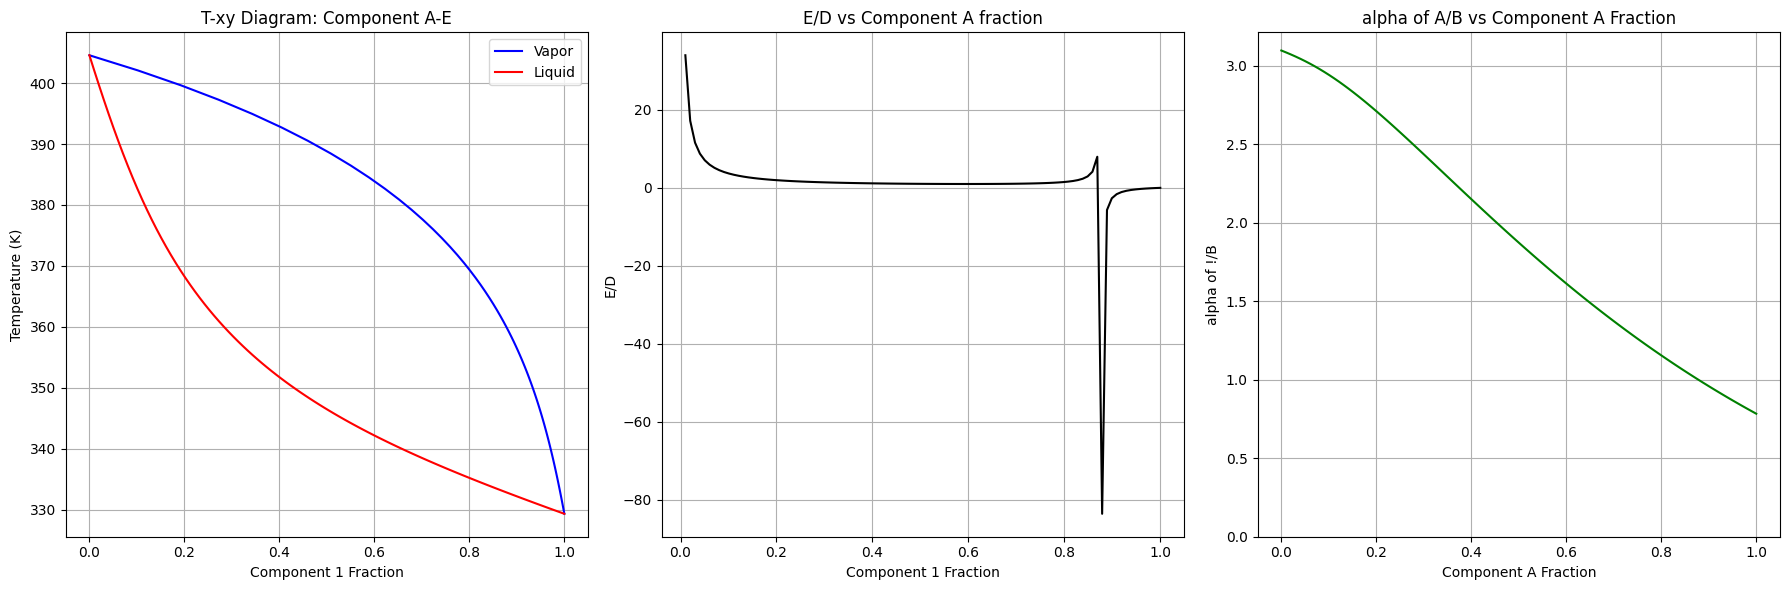

In [11]:
# step4: perform the vle

# define number of data points
n_data = 100
# set composition
# generate all binary combinations for ternary system
x0 = 0.0
xf = 1-x0

# x1-x3 binary (x2=0)
x1_13 = np.linspace(x0, xf, n_data)
x2_13 = np.zeros(n_data)
x3_13 = 1 - x1_13


# combine all binary combinations
x = np.vstack([

    np.column_stack([x1_13, x2_13, x3_13]),

])
# provide nitial guess for temperature

# Extract boiling points for each compound
tb_values = [pure_props[compound]['tb'] for compound in mixture.keys()]
tb1, tb2, tb3 = tb_values  # assuming 3 components
# Create T0 for each binary combination


# x1-x3 binary: T ranges from tb3 (x1=0, x3=1) to tb1 (x1=1, x3=0)
T0_13 = np.linspace(tb3, tb1, n_data)


# Combine all T0 values
T0 = T0_13
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=True)

# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)
psat_pyo = np.empty_like(x)
K = np.empty_like(x)
ED = np.empty_like(T0)

for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

for i in model.psat.keys():
    psat_pyo[i] = model.psat[i].value

# calculate K
K = gamma_pyo * psat_pyo / 1.01325
# calculate E/D
ED = 1 - ((1 - (K[:, 1])) / (x[:, 0] * (K[:, 0] - K[:, 1])))


# Create T-xy plots for all three binary combinations and E/D vs x
# Create T-xy plots for all three binary combinations
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Component 1-2 diagram (first 100 points)
axes[0].plot(y_pyo[:n_data, 0], T_pyo[:n_data], 'b-', label='Vapor')
axes[0].plot(x[:n_data, 0], T_pyo[:n_data], 'r-', label='Liquid')
axes[0].set_ylabel('Temperature (K)')
axes[0].set_xlabel('Component 1 Fraction')
axes[0].set_title('T-xy Diagram: Component A-E')
axes[0].legend()
axes[0].grid()

# E/D vs x diagram
axes[1].plot(x[:, 0], ED, 'k-')
axes[1].set_ylabel('E/D')
axes[1].set_xlabel('Component 1 Fraction')
axes[1].set_title('E/D vs Component A fraction')
axes[1].grid()

# plot K of B
axes[2].plot(x[:, 0], K[:, 0] / K[:, 1], 'g-')
axes[2].set_ylabel('alpha of !/B')
axes[2].set_xlabel('Component A Fraction')
axes[2].set_title('alpha of A/B vs Component A Fraction')
axes[2].set_ylim(0.0, )
axes[2].grid()


plt.tight_layout()
plt.show()



In [12]:
# suggest initial values of x and T
T0 = np.array([350,350])#np.array([(T_max + T_min) / 2, (T_max + T_min) / 2])
#T0=np.array([ pure_props['E']['tb'], pure_props['E']['tb']])

xA = 0.6
x_iso = 0.7
x0 = np.array([[x_iso, 0.0, 1-x_iso],    # Point 0: iso-volatility point
                [xA, 0.0, 1-xA]])          # Point 1: minimum point 
# load unifac data
rk_data, qk_data, interaction_data = load_unifac_data()
#perform the VLE calculation
resuts, model =  pyo_iss(x0, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=False)

#retrieving the solutions
gamma = np.empty_like(x0)
T = np.empty_like(T0)
y = np.empty_like(x0)
x = np.empty_like(x0)
psat = np.empty_like(x0)


for i in model.gamma.keys():
    gamma[i] = model.gamma[i].value

for i in model.T.keys():
    T[i] = model.T[i].value

for i in model.y.keys():
    y[i] = model.y[i].value

for i in model.x.keys():
    x[i] = model.x[i].value

for i in model.psat.keys():
    psat[i] = model.psat[i].value

print(f"The E/D is: {model.obj()}")
print(f"The R is: {model.R.value}")
print(f"The x values are: {x[:,[0,2]]}")

The E/D is: 0.9905488640788487
The R is: 1.7035330713779595
The x values are: [[0.87797439 0.12202561]
 [0.59561003 0.40438997]]
